# Iris Flower Classification

**Name:** Kelvin Apau
**Internship:** Oasis Infobyte, Data Science

## What this project does
There are three kinds of iris flower: Setosa, Versicolor and Virginica. In this project I teach a computer to tell which kind a flower is by looking at four measurements: sepal length, sepal width, petal length and petal width (all in cm).

## Steps
1. Load the data
2. Explore the data (EDA)
3. Make charts
4. Decide which measurements matter most
5. Split the data into a training part and a testing part
6. Train different models
7. Test and compare the models
8. Choose the best model

## Step 1: Import the tools and load the data
The Iris dataset comes built into scikit-learn, so there is nothing to download.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

# Load the dataset
iris = load_iris()

# Put it into a pandas table so it is easy to work with
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Step 2: Exploratory Data Analysis (EDA)
Here I look at the data before building anything. I check its size, the type of each column, whether anything is missing, and the basic statistics.

In [2]:
# Shape = (number of rows, number of columns)
print("Shape:", df.shape)

Shape: (150, 5)


**What this shows:** The data has 150 flowers (rows) and 5 columns: 4 measurements and the species name.

In [3]:
# Data types of each column
print(df.dtypes)

sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object


**What this shows:** The four measurements are decimal numbers (float64). The species column is a category.

In [4]:
# Check for missing (null) values
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


**What this shows:** Every column shows 0, so there are no missing values and no cleaning is needed.

In [5]:
# Descriptive statistics (mean, spread, smallest, largest)
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
# How many flowers of each species?
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

**What this shows:** There are 50 flowers of each species, so the classes are perfectly balanced. This means accuracy is a fair way to judge the models.

## Step 3: Visualisations

### Pairplot
Each small chart compares two measurements, with the colour showing the species. The charts on the diagonal show how each single measurement is spread out for each species.

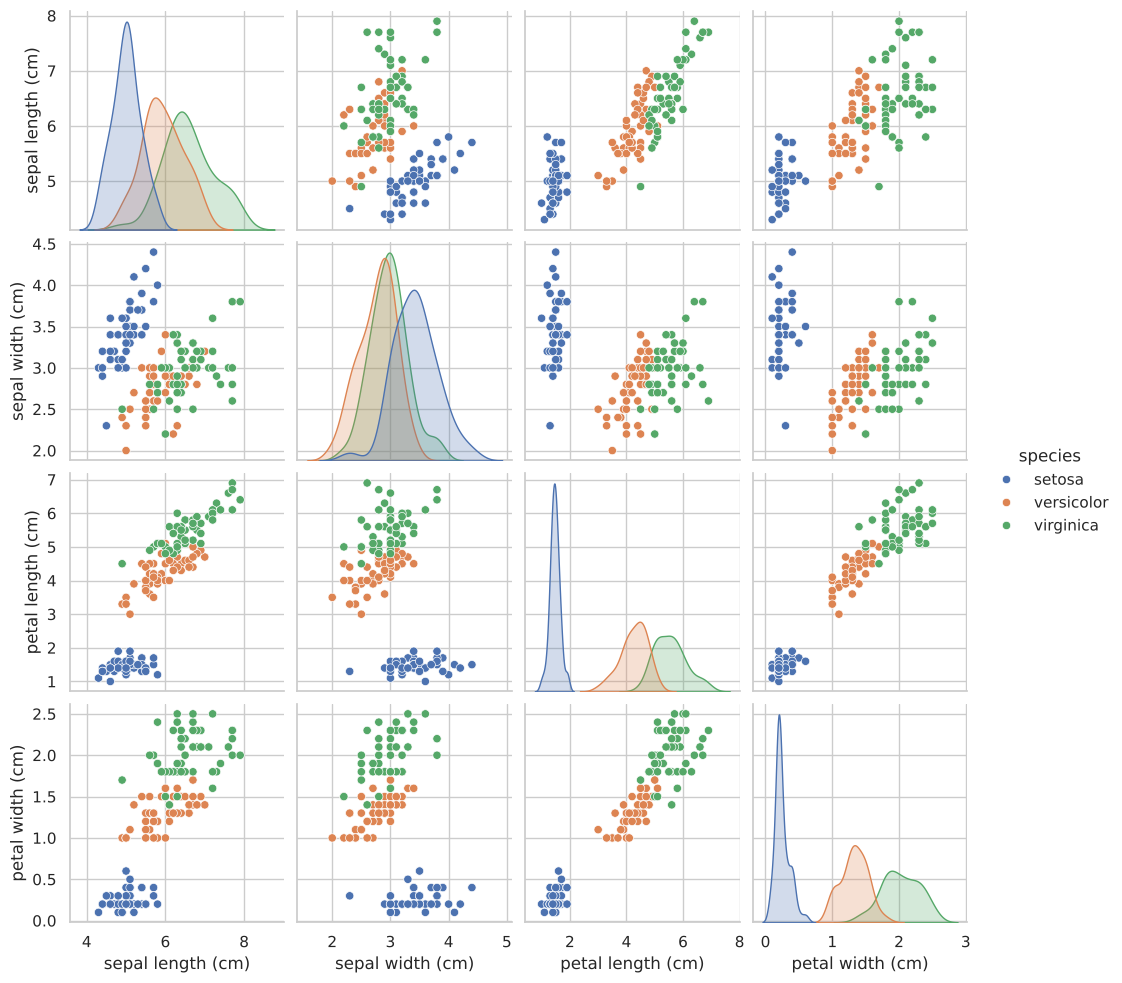

In [7]:
sns.pairplot(df, hue="species", corner=False)
plt.show()

**What this shows:** Setosa (one colour) sits far away from the other two in the petal charts. Versicolor and Virginica overlap a little, so they are harder to separate.

### Box plots
A box plot shows the middle value of each measurement and how spread out it is, for each species.

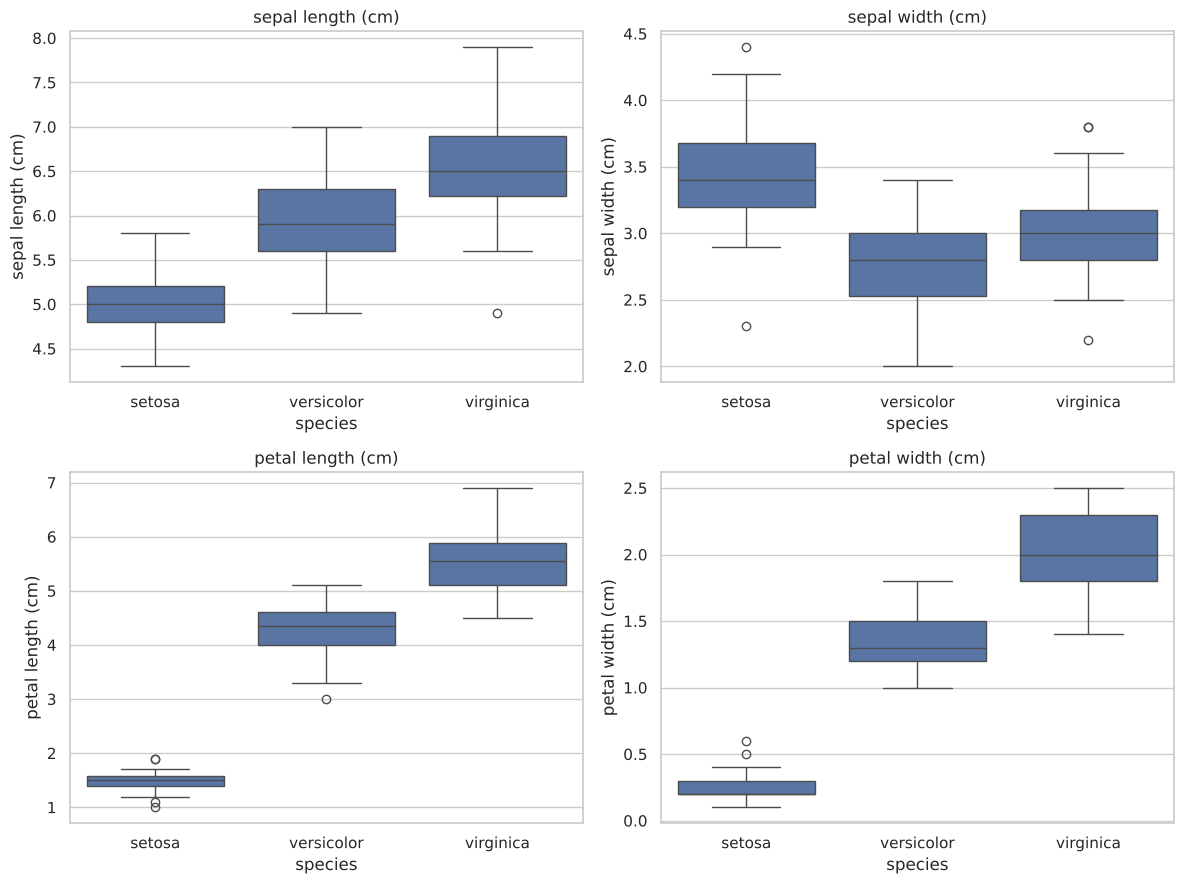

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, feature in zip(axes.flatten(), iris.feature_names):
    sns.boxplot(data=df, x="species", y=feature, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

**What this shows:** For petal length and petal width, the three boxes barely overlap, so these measurements separate the species very well. For sepal width, the boxes overlap a lot, so it helps much less.

## Step 4: Which features are the most useful?
A good feature is one that clearly separates the species. From the charts above:

- **Petal length and petal width** are the most useful. Setosa has very small petals, Versicolor has medium petals, and Virginica has large petals.
- **Sepal length** helps a little.
- **Sepal width** is the least useful because all three species overlap on it.

I will check this again later with the Random Forest model, which can rank the features for us.

## Step 5: Split into training and testing data
I keep 80% of the flowers to teach the model (training set) and hide 20% to test it on flowers it has never seen (test set). Using `stratify=y` makes sure each species appears in equal amounts in both parts.

In [9]:
X = df[iris.feature_names]   # the measurements
y = df["species"]            # the answer we want to predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training flowers:", X_train.shape[0])
print("Testing flowers:", X_test.shape[0])

Training flowers: 120
Testing flowers: 30


## Step 6: Train the models
I train four different classifiers on the same training data:

- **Logistic Regression:** draws straight boundaries between the species.
- **K-Nearest Neighbours (KNN):** looks at the 5 most similar flowers and takes a vote.
- **Decision Tree:** asks a series of yes/no questions about the measurements.
- **Random Forest:** builds many decision trees and combines their votes.

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

# Train every model
for name, model in models.items():
    model.fit(X_train, y_train)
    print("Trained:", name)

Trained: Logistic Regression
Trained: K-Nearest Neighbours
Trained: Decision Tree
Trained: Random Forest


## Step 7: Evaluate each model
For each model I look at three things:

- **Accuracy:** the share of test flowers it got right.
- **Confusion matrix:** a table showing which species were mixed up. The diagonal is correct answers.
- **Classification report:** precision (when it says a species, how often is it right), recall (of all flowers of that species, how many did it find) and F1 (a mix of the two).

Logistic Regression
Accuracy: 0.9667

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



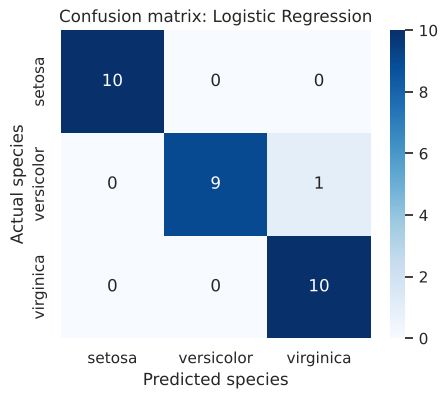

K-Nearest Neighbours
Accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



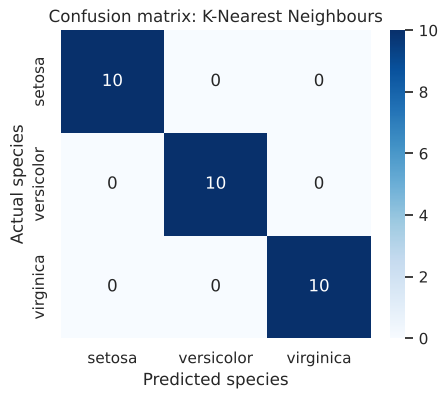

Decision Tree
Accuracy: 0.9333

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



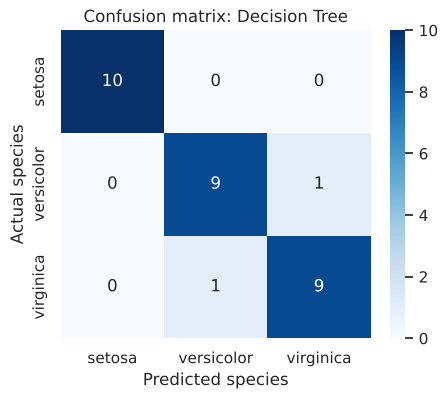

Random Forest
Accuracy: 0.9

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



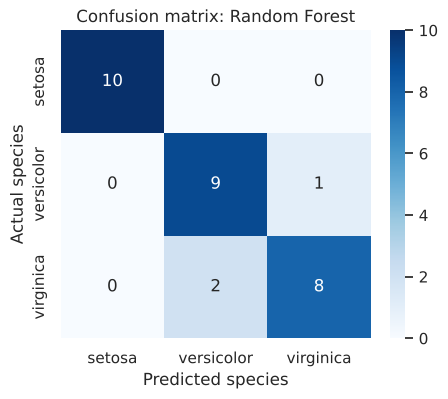

In [11]:
results = {}

for name, model in models.items():
    predictions = model.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    results[name] = acc

    print("=" * 60)
    print(name)
    print("=" * 60)
    print("Accuracy:", round(acc, 4))
    print()
    print("Classification report:")
    print(classification_report(y_test, predictions))

    # Confusion matrix drawn as a heatmap
    cm = confusion_matrix(y_test, predictions, labels=iris.target_names)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    plt.title("Confusion matrix: " + name)
    plt.xlabel("Predicted species")
    plt.ylabel("Actual species")
    plt.show()

### Side by side comparison

K-Nearest Neighbours    1.000000
Logistic Regression     0.966667
Decision Tree           0.933333
Random Forest           0.900000
Name: Accuracy, dtype: float64


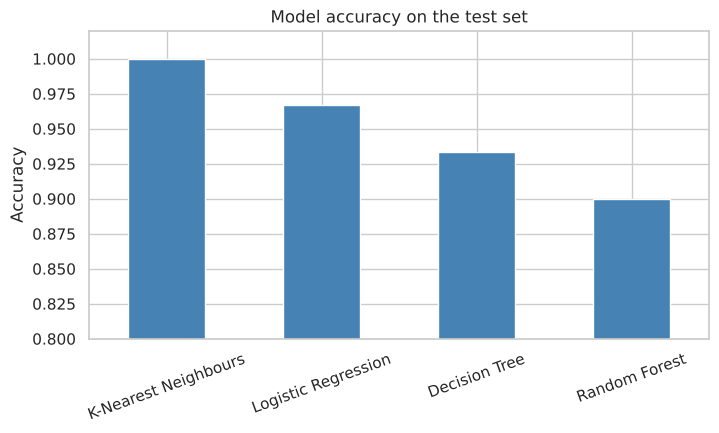

In [12]:
comparison = pd.Series(results, name="Accuracy").sort_values(ascending=False)
print(comparison)

comparison.plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.ylim(0.8, 1.02)
plt.title("Model accuracy on the test set")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.show()

## Step 8: Which feature mattered most?
The Random Forest can tell us how much it relied on each measurement. This checks our guess from Step 4.

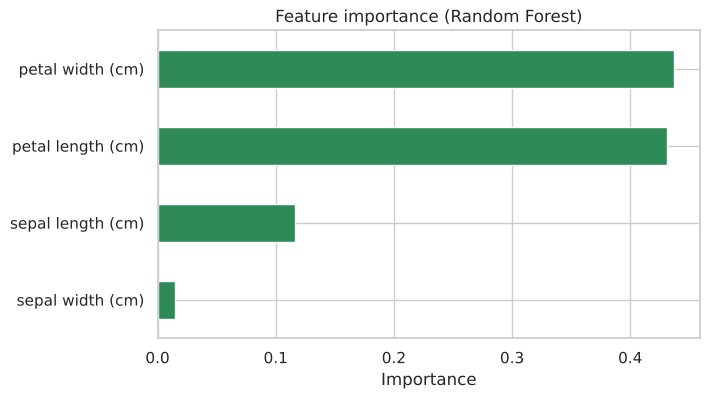

petal width (cm)     0.437185
petal length (cm)    0.431466
sepal length (cm)    0.116349
sepal width (cm)     0.015000
dtype: float64


In [13]:
importances = pd.Series(
    models["Random Forest"].feature_importances_,
    index=iris.feature_names
).sort_values()

importances.plot(kind="barh", figsize=(7, 4), color="seagreen")
plt.title("Feature importance (Random Forest)")
plt.xlabel("Importance")
plt.show()

print(importances.sort_values(ascending=False))

**What this shows:** Petal length and petal width carry most of the importance, and sepal width carries the least. This matches what the charts showed in Step 3.

## Step 9: Best model and conclusion

In [14]:
best_name = comparison.index[0]
print("Best model on this test set:", best_name)
print("Accuracy:", round(comparison.iloc[0], 4))

Best model on this test set: K-Nearest Neighbours
Accuracy: 1.0


### Conclusion
- All four models did very well on this dataset, because the species are clearly separated by their petal measurements.
- The best model is **K-Nearest Neighbours**. It scored 100% accuracy (30 out of 30) on flowers it had never seen, and its confusion matrix has no mistakes at all. Logistic Regression came next at about 97%, then the Decision Tree at about 93%, then the Random Forest at 90%.
- Setosa was classified perfectly by every model. The only mistakes were between Versicolor and Virginica, which overlap a little.
- **Petal length** and **petal width** are the most discriminative features.
- **Note:** The test set has only 30 flowers, so one extra mistake changes the accuracy by about 3%. The models score close together, so the ranking could change with a different split. It would be wrong to say Random Forest is a weak model just because it came last here. For a more reliable comparison, cross validation could be used as a next step.